# MLWDF Weight Sensitivity Analysis: $\Gamma_W$ (sweeping `Gamma_configs`)

**Dataset:** `results/Sensitivity_Weight_Final_Iter`, generated using `MLDW_params_sweep_in_weight_final_iters.py`.

**Experimental configuration:** SAT = 90%, PER = 10%, $\Gamma_0=\Gamma_1=1$, traffic distribution of 66% / 34%, 10 runs, and 60 s per run.

## Weight implementation

According to the `conf_Scheduler.json` configuration, the scheduling utility is defined as:

$$
V_i = \gamma_i \left(
\Gamma_W \, \mathrm{HOL}_i[\mu s]
+
\Gamma_Q \, \mathrm{Bytes}_i
\right).
$$

Since the scheduler always serves the flow with the highest $V_i$, in a saturated regime, the scheduling process tends to balance the utilities of the competing flows, such that $V_0 \approx V_1$.

Using Little's law, we can approximate the queue occupancy as:

$$
\mathrm{Bytes}_i \approx \lambda_i \, \mathrm{HOL}_i,
$$

where $\lambda_i$ denotes the traffic arrival rate in bytes/$\mu$s. Therefore, assuming $\gamma_0=\gamma_1$:

$$
\gamma_0 \left(\Gamma_W+\Gamma_Q\lambda_0\right)
\mathrm{HOL}_0
=
\gamma_1 \left(\Gamma_W+\Gamma_Q\lambda_1\right)
\mathrm{HOL}_1.
$$

Rearranging, we obtain the following approximation for the ratio between the average HoL delays:

$$
\boxed{
\frac{\mathrm{HOL}_0}{\mathrm{HOL}_1}
=
\frac{\gamma_1}{\gamma_0}
\cdot
\frac{\Gamma_W+\Gamma_Q\lambda_1}
{\Gamma_W+\Gamma_Q\lambda_0}
}
$$

## Interpretation of the different configurations

- **$\Gamma_Q=0$ (W1_Q0):** The ratio becomes $\mathrm{HOL}_0/\mathrm{HOL}_1=\Gamma_1/\Gamma_0$. Thus, for equal flow priorities ($\Gamma_0=\Gamma_1$), the scheduler tends to equalize the HoL delays.

- **$\Gamma_W=0$ (W0_Q1):** The ratio becomes $\mathrm{HOL}_0/\mathrm{HOL}_1=\lambda_1/\lambda_0\approx 0.5$. In this case, the scheduler tends to equalize queue occupancy in bytes rather than delays. Consequently, the slower flow experiences approximately twice the HoL delay of the faster flow.

- **$\Gamma_W\gg\Gamma_Q\lambda_i$:** The ratio approaches $\mathrm{HOL}_0/\mathrm{HOL}_1\rightarrow\Gamma_1/\Gamma_0$. For equal flow priorities, the HoL delays tend to be equalized, and the contribution of the queue occupancy term becomes negligible. In this particular setup, the transition occurs around $\Gamma_W/\Gamma_Q\approx 1$--$2$ bytes/$\mu$s. For instance, with $\Gamma_W=10$, the ratio is already approximately 0.85, while for values of 100 and 1000 it is practically equal to 1.

**Key observation:** The relative importance of the two scheduling terms is determined by the ratio $\Gamma_W/\Gamma_Q$ compared with the traffic arrival rates $\lambda_i$ (in bytes/$\mu$s). This ratio establishes the transition between queue-dominated and delay-dominated scheduling regimes.

In [9]:
import os, re, glob, tarfile, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURACIÓN
# ==========================================
RESULTS_ROOT = "./results"
SENS_FOLDER = "FINAL_Sensitivity_Weight_Final_Iter"          # new sweep W10/W100/W1000 (Q=1)
# Older folders (W1_Q1, W1_Q0, W0_Q1)  just in case we want to complement the analysis with  eta_W en gamma=1 (opcional)
OLD_FOLDERS = ["Poisson_2_1_conMDlogs_ALL", "Poisson_2_1_conMDlogs_ALL_ITERS5to10"]
INCLUDE_OLD = False

TARGET_SAT = 90
TARGET_PER = 10
TARGET_GAMMA = 1.0
NUM_RUNS = 10

# Load Params (equal to the sweep script)
CHANNEL_MBPS = 27
STREAMS_LOAD = [0.66, 0.34]
STREAM_IDS = {0: "S0 Non-Crit (2x)", 4: "S1 Crit (1x)"}   # StreamID QUIC -> label

eff_rate = CHANNEL_MBPS * (1 - TARGET_PER / 100) * (TARGET_SAT / 100)       # Mbps
LAMBDA_NOM = {0: eff_rate * STREAMS_LOAD[0] / 8.0, 4: eff_rate * STREAMS_LOAD[1] / 8.0}  # bytes/us
print("Tasa nominal por flujo [bytes/us]:", {k: round(v, 3) for k, v in LAMBDA_NOM.items()})

Tasa nominal por flujo [bytes/us]: {0: 1.804, 4: 0.929}


In [10]:
# ==========================================
# READING OF LOGS (decompressed folder or SAT90.tar.gz)
# ==========================================
class RunSource(object):
    """Abstrae el acceso a los ficheros de un SAT (directorio o tar.gz)."""
    def __init__(self, gamma_dir, sat):
        self.gamma_dir = gamma_dir
        self.sat = sat
        self.tar_path = os.path.join(gamma_dir, "SAT{}.tar.gz".format(sat))
        self.dir_path = os.path.join(gamma_dir, "SAT{}".format(sat))
        self._tar = None
        self._members = None

    def available(self):
        return os.path.isdir(self.dir_path) or os.path.exists(self.tar_path)

    def _open_tar(self):
        if self._tar is None and os.path.exists(self.tar_path) and not os.path.isdir(self.dir_path):
            self._tar = tarfile.open(self.tar_path, "r:gz")
            self._members = {m.name: m for m in self._tar.getmembers() if m.isfile()}
        return self._tar

    def read(self, rel):
        """rel: ruta relativa dentro de SAT{sat}/ -> bytes o None"""
        full = os.path.join(self.dir_path, rel)
        if os.path.isdir(self.dir_path):
            return open(full, "rb").read() if os.path.exists(full) else None
        tar = self._open_tar()
        if tar is None:
            return None
        key = "SAT{}/{}".format(self.sat, rel)
        m = self._members.get(key)
        return tar.extractfile(m).read() if m is not None else None

    def runs(self, per):
        pat = re.compile(r"DELAY0_PER{}/RUN(\d+)/".format(per))
        if os.path.isdir(self.dir_path):
            d = os.path.join(self.dir_path, "DELAY0_PER{}".format(per))
            if not os.path.isdir(d):
                return []
            return sorted(int(x[3:]) for x in os.listdir(d) if x.startswith("RUN"))
        self._open_tar()
        if self._members is None:
            return []
        return sorted({int(m.group(1)) for m in (pat.search(n) for n in self._members) if m})

    def close(self):
        if self._tar is not None:
            self._tar.close()
            self._tar = None


def parse_cols(raw, ncols):
    if raw is None:
        return None
    arr = np.loadtxt(io.BytesIO(raw), usecols=range(ncols), ndmin=2)
    return arr if arr.size else None


def e2e_delay_ms(src, run, suffix):
    base = "DELAY0_PER{}/RUN{}".format(TARGET_PER, run)
    tx = parse_cols(src.read(base + "/go_client/logClient_{}.log".format(suffix)), 1)
    rx = parse_cols(src.read(base + "/go_server/logServer_{}.log".format(suffix)), 1)
    if tx is None or rx is None:
        return np.array([])
    n = min(len(tx), len(rx))
    d = (rx[:n, 0] - tx[:n, 0]) * 1e-3
    return d[d >= 0]


def scheduler_stats(src, run):
    """Medias por flujo de Bytes en cola y HOL (MaxDelay) + correlación ventana 100 ms."""
    base = "DELAY0_PER{}/RUN{}/go_client/".format(TARGET_PER, run)
    q = parse_cols(src.read(base + "logSchedulerMLWDF.log"), 3)              # Time, Str, Bytes
    s = parse_cols(src.read(base + "logSchedulerSojournTime_MLWDF.log"), 4)  # Time, Str, Sojourn, MaxDelay
    out = {}
    if q is None or s is None:
        return out
    t0 = min(q[0, 0], s[0, 0])
    for sid in STREAM_IDS:
        qs = q[q[:, 1] == sid]
        ss = s[s[:, 1] == sid]
        if len(qs) == 0 or len(ss) == 0:
            continue
        # correlación macro (bins de 100 ms) entre cola y HOL
        bq = pd.Series(qs[:, 2]).groupby(((qs[:, 0] - t0) // 1e5).astype(int)).mean()
        bs = pd.Series(ss[:, 3]).groupby(((ss[:, 0] - t0) // 1e5).astype(int)).mean()
        j = pd.concat([bq, bs], axis=1, join="inner")
        out[sid] = {
            "Q_bytes": float(qs[:, 2].mean()),
            "HOL_us": float(ss[:, 3].mean()),
            "corr_Q_HOL": float(j.iloc[:, 0].corr(j.iloc[:, 1])) if len(j) > 2 else np.nan,
        }
    return out

In [11]:
# ==========================================
# DESCUBRIMIENTO DE CONFIGURACIONES
# ==========================================
def parse_eta(label):
    m = re.match(r"W([\d\.]+)_Q([\d\.]+)", label)
    return (float(m.group(1)), float(m.group(2))) if m else (np.nan, np.nan)

configs = []   # dicts: label, W, Q, campaign, sources[]
gamma_tag = "GAMMA_CRIT_{:.1f}".format(TARGET_GAMMA)

for d in sorted(glob.glob(os.path.join(RESULTS_ROOT, SENS_FOLDER, "MLWDF", "*", gamma_tag))):
    label = d.split(os.sep)[-2]
    W, Q = parse_eta(label)
    configs.append({"label": label, "W": W, "Q": Q, "campaign": "Sensitivity (60 s)",
                    "sources": [RunSource(d, TARGET_SAT)]})

if INCLUDE_OLD:
    old = {}
    for f in OLD_FOLDERS:
        for d in sorted(glob.glob(os.path.join(RESULTS_ROOT, f, "MLWDF", "*", gamma_tag))):
            old.setdefault(d.split(os.sep)[-2], []).append(RunSource(d, TARGET_SAT))
    for label, srcs in sorted(old.items()):
        W, Q = parse_eta(label)
        configs.append({"label": label, "W": W, "Q": Q, "campaign": "Poisson_2_1 (120 s)", "sources": srcs})

# Referencias sin gamma (RR / STBP) si ya existen en la carpeta nueva
# for sched in ["RR", "STBP"]:
#     d = os.path.join(RESULTS_ROOT, SENS_FOLDER, sched)
#     if os.path.isdir(d):
#         configs.append({"label": sched, "W": np.nan, "Q": np.nan, "campaign": "Sensitivity (60 s)",
#                         "sources": [RunSource(d, TARGET_SAT)]})

configs = [c for c in configs if any(s.available() for s in c["sources"])]
for c in configs:
    print("{:<10} W={:<7} Q={:<4} [{}]".format(c["label"], c["W"], c["Q"], c["campaign"]))

W0.001_Q1  W=0.001   Q=1.0  [Sensitivity (60 s)]
W0.01_Q1   W=0.01    Q=1.0  [Sensitivity (60 s)]
W0.1_Q1    W=0.1     Q=1.0  [Sensitivity (60 s)]
W1000_Q1   W=1000.0  Q=1.0  [Sensitivity (60 s)]
W100_Q1    W=100.0   Q=1.0  [Sensitivity (60 s)]
W10_Q1     W=10.0    Q=1.0  [Sensitivity (60 s)]
W1_Q1      W=1.0     Q=1.0  [Sensitivity (60 s)]


In [12]:
# ==========================================
# EXTRACCIÓN POR RUN (multiplexa todas las fuentes de cada configuración)
# ==========================================
run_rows = []     # una fila por (config, run, stream)
delay_pool = {}   # (label, sid) -> lista de arrays de retardo e2e (ms)

for c in configs:
    seen = set()
    for src in c["sources"]:
        if not src.available():
            continue
        for run in src.runs(TARGET_PER):
            if run in seen or run >= NUM_RUNS:
                continue
            d = {0: e2e_delay_ms(src, run, "1_1"), 4: e2e_delay_ms(src, run, "1_2")}
            if d[0].size == 0 or d[4].size == 0:
                continue          # RUN incompleto (simulación aún en curso)
            seen.add(run)
            sch = scheduler_stats(src, run) if c["label"] not in ("RR", "STBP") else {}
            for sid in STREAM_IDS:
                delay_pool.setdefault((c["label"], sid), []).append(d[sid])
                row = {"label": c["label"], "W": c["W"], "Q": c["Q"], "campaign": c["campaign"],
                       "run": run, "sid": sid,
                       "e2e_mean": d[sid].mean(), "e2e_med": np.median(d[sid]),
                       "e2e_p95": np.percentile(d[sid], 95)}
                row.update(sch.get(sid, {}))
                run_rows.append(row)
        src.close()
    print("[{}] RUNs válidos: {}".format(c["label"], sorted(seen)))

df_runs = pd.DataFrame(run_rows)
df_runs.head()

[W0.001_Q1] RUNs válidos: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[W0.01_Q1] RUNs válidos: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[W0.1_Q1] RUNs válidos: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[W1000_Q1] RUNs válidos: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[W100_Q1] RUNs válidos: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[W10_Q1] RUNs válidos: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[W1_Q1] RUNs válidos: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


,label,W,Q,campaign,run,sid,e2e_mean,e2e_med,e2e_p95,Q_bytes,HOL_us,corr_Q_HOL
0,W0.001_Q1,0.001,1.0,Sensitivity (60 s),0,0,395.134541,306.331,788.4796,6.935424e+05,3.941801e+05,0.911870
1,W0.001_Q1,0.001,1.0,Sensitivity (60 s),0,4,746.052491,578.012,1516.2476,6.766077e+05,7.368915e+05,0.992543
2,W0.001_Q1,0.001,1.0,Sensitivity (60 s),1,0,1262.764589,1134.676,2390.4214,2.157515e+06,1.278844e+06,0.840686
3,W0.001_Q1,0.001,1.0,Sensitivity (60 s),1,4,2431.618678,2356.946,4400.3980,2.142422e+06,2.379458e+06,0.950819
4,W0.001_Q1,0.001,1.0,Sensitivity (60 s),2,0,495.812132,333.190,976.7982,8.683081e+05,4.950467e+05,0.909990


In [13]:
# ==========================================
# EMPIRICAL RATIOS vs THEORETICAL PREDICTION
# ==========================================
def theo_ratio(W, Q, l0, l1, g0=1.0, g1=TARGET_GAMMA):
    return (g1 / g0) * (W + Q * l1) / (W + Q * l0)

_tmp = df_runs.copy()
_tmp[["W", "Q"]] = _tmp[["W", "Q"]].fillna(-1)          # RR/STBP sin eta (pivot no admite NaN en el índice)
wide = _tmp.pivot_table(index=["label", "W", "Q", "campaign", "run"], columns="sid",
                        values=[c for c in ["e2e_mean", "e2e_med", "Q_bytes", "HOL_us"] if c in _tmp]).reset_index()
wide.columns = ["{}_{}".format(a, b) if b != "" else a for a, b in wide.columns]
wide.loc[wide["W"] < 0, ["W", "Q"]] = np.nan

wide["ratio_e2e_mean"] = wide["e2e_mean_0"] / wide["e2e_mean_4"]
wide["ratio_e2e_med"] = wide["e2e_med_0"] / wide["e2e_med_4"]
if "HOL_us_0" in wide:
    wide["ratio_HOL"] = wide["HOL_us_0"] / wide["HOL_us_4"]
    wide["ratio_Q"] = wide["Q_bytes_0"] / wide["Q_bytes_4"]
    # tasa efectiva de cada flujo (Little): lambda_i = Bytes_i / HOL_i  [bytes/us]
    wide["lam0_eff"] = wide["Q_bytes_0"] / wide["HOL_us_0"]
    wide["lam4_eff"] = wide["Q_bytes_4"] / wide["HOL_us_4"]
    wide["ratio_theo_eff"] = theo_ratio(wide["W"], wide["Q"], wide["lam0_eff"], wide["lam4_eff"])
    # fracción del peso V debida al término de retardo (por flujo)
    for s in (0, 4):
        num = wide["W"] * wide["HOL_us_{}".format(s)]
        wide["fracW_{}".format(s)] = num / (num + wide["Q"] * wide["Q_bytes_{}".format(s)])
wide["ratio_theo_nom"] = theo_ratio(wide["W"], wide["Q"], LAMBDA_NOM[0], LAMBDA_NOM[4])

agg_cols = [c for c in ["e2e_mean_0", "e2e_mean_4", "ratio_e2e_mean", "ratio_e2e_med", "ratio_HOL",
                        "ratio_theo_eff", "ratio_theo_nom", "ratio_Q", "lam0_eff", "lam4_eff",
                        "fracW_0", "fracW_4"] if c in wide]
grp = wide.groupby(["label", "campaign"])
summary = grp[agg_cols].agg(["mean", "std"])
summary.columns = ["_".join(col) for col in summary.columns]
summary = grp[["W", "Q"]].first().join(summary)
summary["n_runs"] = grp.size()
summary = summary.reset_index().sort_values(["W", "Q"], na_position="last").reset_index(drop=True)

show = ["label", "n_runs", "e2e_mean_0_mean", "e2e_mean_4_mean", "ratio_e2e_mean_mean", "ratio_e2e_mean_std",
        "ratio_HOL_mean", "ratio_theo_eff_mean", "ratio_theo_nom_mean", "ratio_Q_mean", "fracW_0_mean"]
pd.set_option("display.width", 250)
print(summary[[c for c in show if c in summary]].to_string(index=False, float_format=lambda x: "{:.3f}".format(x)))

    label  n_runs  e2e_mean_0_mean  e2e_mean_4_mean  ratio_e2e_mean_mean  ratio_e2e_mean_std  ratio_HOL_mean  ratio_theo_eff_mean  ratio_theo_nom_mean  ratio_Q_mean  fracW_0_mean
W0.001_Q1      10          497.572          944.482                0.539               0.024           0.544                0.523                0.515         1.042         0.001
 W0.01_Q1      10          369.930          693.556                0.546               0.039           0.549                0.523                0.518         1.053         0.006
  W0.1_Q1      10          490.240          888.461                0.564               0.026           0.568                0.547                0.541         1.088         0.053
    W1_Q1      10          600.751          861.171                0.699               0.004           0.706                0.693                0.688         1.356         0.361
   W10_Q1      10          638.178          679.332                0.941               0.006           0.

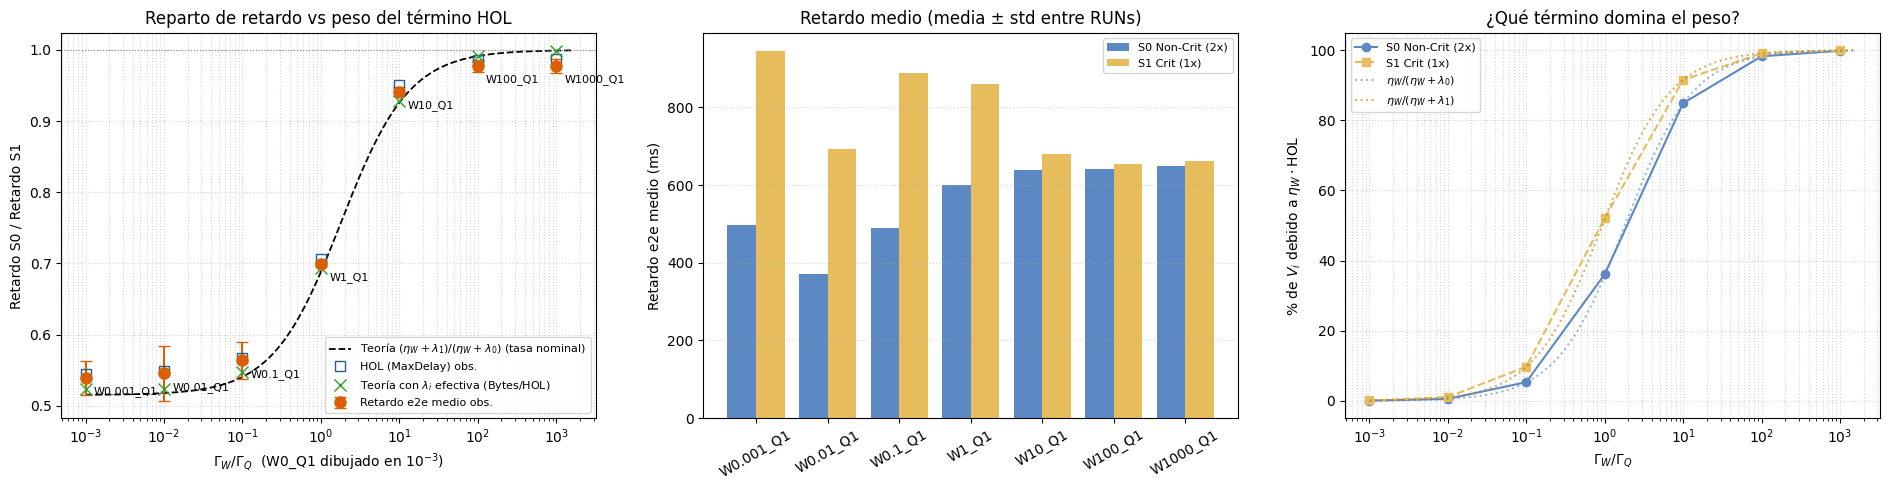

In [14]:
# ==========================================
# FIGURE 1: RATIO S0/S1 vs eta_W/eta_Q  (obs. vs THEORY)
# ==========================================
mlw = summary[summary["Q"] > 0].copy()
mlw_eta = mlw["W"] / mlw["Q"]
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

ax = axes[0]
x_line = np.logspace(-3, 3.2, 300)
ax.plot(x_line, theo_ratio(x_line, 1, LAMBDA_NOM[0], LAMBDA_NOM[4]), "k--", lw=1.3,
        label=r"Teoría $(\eta_W+\lambda_1)/(\eta_W+\lambda_0)$ (tasa nominal)")
ax.errorbar(mlw_eta.clip(lower=1e-3), mlw["ratio_e2e_mean_mean"], yerr=mlw["ratio_e2e_mean_std"],
            fmt="o", ms=8, capsize=4, color="#d95f02", label="Retardo e2e medio obs.")
if "ratio_HOL_mean" in mlw:
    ax.plot(mlw_eta.clip(lower=1e-3), mlw["ratio_HOL_mean"], "s", ms=7, mfc="none", color="#2b5c8f",
            label="HOL (MaxDelay) obs.")
    ax.plot(mlw_eta.clip(lower=1e-3), mlw["ratio_theo_eff_mean"], "x", ms=9, color="#2ca02c",
            label=r"Teoría con $\lambda_i$ efectiva (Bytes/HOL)")
for _, r in mlw.iterrows():
    ax.annotate(r["label"], (max(r["W"] / r["Q"], 1e-3), r["ratio_e2e_mean_mean"]),
                textcoords="offset points", xytext=(6, -12), fontsize=8)
ax.axhline(1, color="grey", lw=0.8, ls=":")
ax.set_xscale("log")
ax.set_xlabel(r"$\Gamma_W/\Gamma_Q$  (W0_Q1 dibujado en $10^{-3}$)")
ax.set_ylabel(r"Retardo S0 / Retardo S1")
ax.set_title("Reparto de retardo vs peso del término HOL")
ax.grid(True, which="both", ls=":", alpha=0.5)
ax.legend(fontsize=8)

# Panel 2: retardo e2e medio por flujo
ax = axes[1]
order = summary["label"].tolist()
xpos = np.arange(len(order))
ax.bar(xpos - 0.2, summary["e2e_mean_0_mean"], 0.4, capsize=3,
       color="#5c88c4", label=STREAM_IDS[0])
ax.bar(xpos + 0.2, summary["e2e_mean_4_mean"], 0.4, capsize=3,
       color="#e6bc5c", label=STREAM_IDS[4])
ax.set_xticks(xpos)
ax.set_xticklabels(order, rotation=30)
ax.set_ylabel("Retardo e2e medio (ms)")
ax.set_title("Retardo medio (media ± std entre RUNs)")
ax.grid(True, axis="y", ls=":", alpha=0.5)
ax.legend(fontsize=8)

# Panel 3: % del peso V debido al término de retardo
ax = axes[2]
if "fracW_0_mean" in mlw:
    ax.plot(mlw_eta.clip(lower=1e-3), 100 * mlw["fracW_0_mean"], "o-", color="#5c88c4", label=STREAM_IDS[0])
    ax.plot(mlw_eta.clip(lower=1e-3), 100 * mlw["fracW_4_mean"], "s--", color="#e6bc5c", label=STREAM_IDS[4])
    xl = np.logspace(-3, 3.2, 200)
    ax.plot(xl, 100 * xl / (xl + LAMBDA_NOM[0]), ":", color="#5c88c4", alpha=0.6, label=r"$\eta_W/(\eta_W+\lambda_0)$")
    ax.plot(xl, 100 * xl / (xl + LAMBDA_NOM[4]), ":", color="#b38600", alpha=0.6, label=r"$\eta_W/(\eta_W+\lambda_1)$")
ax.set_xscale("log")
ax.set_xlabel(r"$\Gamma_W/\Gamma_Q$")
ax.set_ylabel(r"% de $V_i$ debido a $\eta_W\cdot$HOL")
ax.set_title("¿Qué término domina el peso?")
ax.grid(True, which="both", ls=":", alpha=0.5)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
# 1. Puntos Panel 1
panel1_df = mlw[["ratio_e2e_mean_mean", "ratio_e2e_mean_std"]].copy()
panel1_df["eta_ratio"] = mlw_eta.clip(lower=1e-3)
if "ratio_HOL_mean" in mlw:
    panel1_df["ratio_hol_obs"] = mlw["ratio_HOL_mean"]
if "ratio_theo_eff_mean" in mlw:
    panel1_df["ratio_theo_eff"] = mlw["ratio_theo_eff_mean"]
panel1_df["label"] = mlw["label"]
panel1_df.to_csv("panel1_points.csv", index=False)

# 2. Curva teórica Panel 1
x_theo = np.logspace(-3, 3.2, 50)
y_theo = theo_ratio(x_theo, 1, LAMBDA_NOM[0], LAMBDA_NOM[4])
pd.DataFrame({"eta_ratio": x_theo, "theory_ratio": y_theo}).to_csv("panel1_theory_curve.csv", index=False)

# 3. Puntos Panel 3
panel3_df = pd.DataFrame({
    "eta_ratio": mlw_eta.clip(lower=1e-3),
    "fracW_s0_pct": 100 * mlw["fracW_0_mean"],
    "fracW_s1_pct": 100 * mlw["fracW_4_mean"]
})
panel3_df.to_csv("panel3_points.csv", index=False)

# 4. Curvas teóricas Panel 3
x_theo3 = np.logspace(-3, 3.2, 50)
pd.DataFrame({
    "eta_ratio": x_theo3,
    "theo_s0_pct": 100 * x_theo3 / (x_theo3 + LAMBDA_NOM[0]),
    "theo_s1_pct": 100 * x_theo3 / (x_theo3 + LAMBDA_NOM[4])
}).to_csv("panel3_theory_curves.csv", index=False)

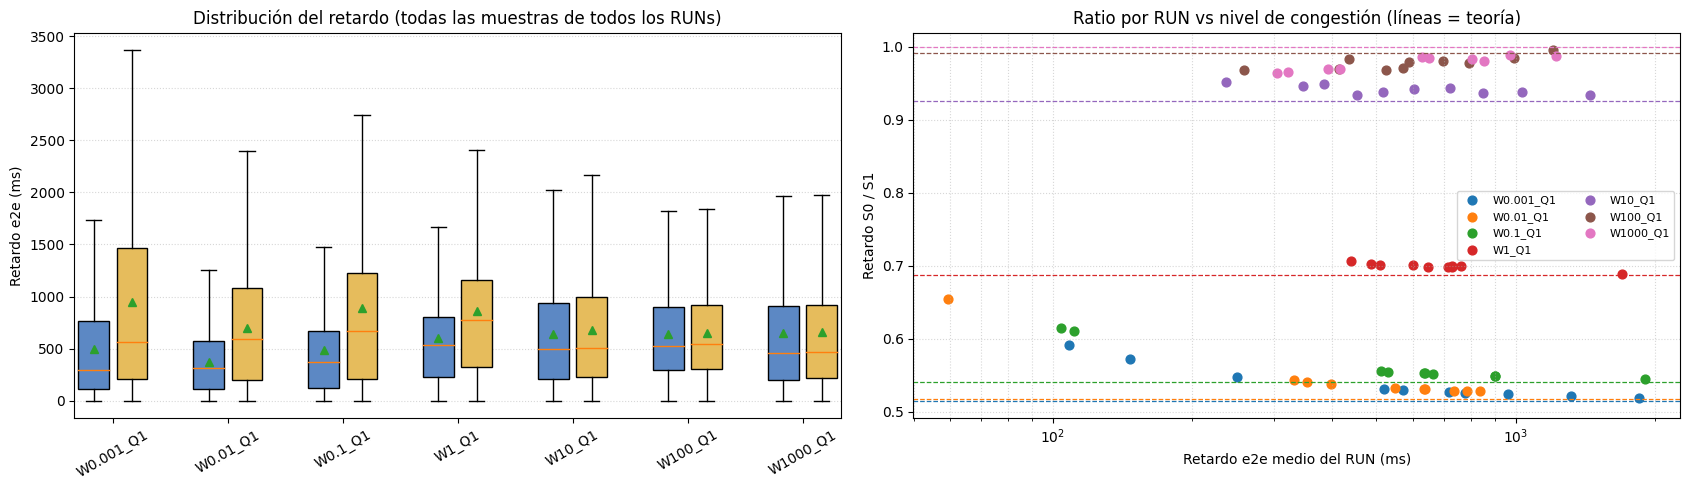

In [16]:
# ==========================================
# FIGURE 2: E2E DISTRIBUTION (boxplots) Y RATIO AMONG RUNs (robustness)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(17, 5))

ax = axes[0]
data, pos, cols = [], [], []
for i, lab in enumerate(order):
    for k, sid in enumerate(STREAM_IDS):
        arrs = delay_pool.get((lab, sid), [])
        if arrs:
            data.append(np.concatenate(arrs))
            pos.append(i * 3 + k)
            cols.append("#5c88c4" if sid == 0 else "#e6bc5c")
bp = ax.boxplot(data, positions=pos, widths=0.8, showfliers=False, showmeans=True, patch_artist=True)
for patch, c in zip(bp["boxes"], cols):
    patch.set_facecolor(c)
ax.set_xticks([i * 3 + 0.5 for i in range(len(order))])
ax.set_xticklabels(order, rotation=30)
ax.set_ylabel("Retardo e2e (ms)")
ax.set_title("Distribución del retardo (todas las muestras de todos los RUNs)")
ax.grid(True, axis="y", ls=":", alpha=0.5)

# El retardo absoluto varía mucho entre RUNs (canal con PER), pero el RATIO es estable
ax = axes[1]
cmap = plt.get_cmap("tab10")
for i, lab in enumerate(order):
    sub = wide[wide["label"] == lab]
    ax.scatter(0.5 * (sub["e2e_mean_0"] + sub["e2e_mean_4"]), sub["ratio_e2e_mean"], s=40,
               color=cmap(i % 10), label=lab)
    if lab in mlw["label"].values:
        ax.axhline(float(mlw.loc[mlw["label"] == lab, "ratio_theo_nom_mean"]), color=cmap(i % 10), ls="--", lw=0.9)
ax.set_xscale("log")
ax.set_xlabel("Retardo e2e medio del RUN (ms)")
ax.set_ylabel("Retardo S0 / S1")
ax.set_title("Ratio por RUN vs nivel de congestión (líneas = teoría)")
ax.grid(True, which="both", ls=":", alpha=0.5)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

In [17]:
# ==========================================
# EXPORT CSV FOR TIKZ (STYLE: W,lw,lq,med,uq,uw,xaux,avg,max,min,stream,sat,per,folder)
# ==========================================
def box_row(arr):
    q1, med, q3 = np.percentile(arr, [25, 50, 75])
    iqr = q3 - q1
    return {"lw": float(arr[arr >= q1 - 1.5 * iqr].min()), "lq": q1, "med": med, "uq": q3,
            "uw": float(arr[arr <= q3 + 1.5 * iqr].max()), "xaux": iqr,
            "avg": float(arr.mean()), "max": float(arr.max()), "min": float(arr.min())}

rows = []
for lab in order:
    c = next(x for x in configs if x["label"] == lab)
    for sid, stream in [(0, "1_1"), (4, "1_2")]:
        arrs = delay_pool.get((lab, sid), [])
        if not arrs:
            continue
        r = {"W": c["W"], "Q": c["Q"]}
        r.update(box_row(np.concatenate(arrs)))
        r.update({"stream": stream, "sat": "SAT{}".format(TARGET_SAT), "per": TARGET_PER, "folder": lab})
        rows.append(r)
df_box = pd.DataFrame(rows)
df_box.to_csv("Sensitivity_eta_SAT{}_PER{}_boxplot_tikz.csv".format(TARGET_SAT, TARGET_PER), index=False)
summary.to_csv("Sensitivity_eta_SAT{}_PER{}_ratios_tikz.csv".format(TARGET_SAT, TARGET_PER), index=False)
print("✓ CSVs guardados")
df_box

✓ CSVs guardados


,W,Q,lw,lq,med,uq,uw,xaux,avg,max,min,stream,sat,per,folder
0,0.001,1.0,0.520,116.21900,298.4530,762.56975,1732.065,646.35075,497.571614,33277.310,0.520,1_1,SAT90,10,W0.001_Q1
1,0.001,1.0,0.676,203.85675,559.2635,1468.10050,3364.444,1264.24375,944.482274,33277.286,0.676,1_2,SAT90,10,W0.001_Q1
2,0.010,1.0,0.607,115.18700,315.2590,571.76550,1256.542,456.57850,369.930498,31591.738,0.607,1_1,SAT90,10,W0.01_Q1
3,0.010,1.0,0.657,197.92075,591.8970,1079.35275,2401.331,881.43200,693.555839,31978.996,0.657,1_2,SAT90,10,W0.01_Q1
4,0.100,1.0,0.545,123.07300,368.9615,665.12875,1478.092,542.05575,490.239581,33295.800,0.545,1_1,SAT90,10,W0.1_Q1
5,0.100,1.0,0.564,211.09200,673.7975,1225.47075,2746.929,1014.37875,888.461470,33696.113,0.564,1_2,SAT90,10,W0.1_Q1
6,1.000,1.0,0.571,230.43500,536.5740,805.30650,1667.560,574.87150,600.751418,33527.416,0.571,1_1,SAT90,10,W1_Q1
7,1.000,1.0,0.636,327.10025,770.7140,1160.99625,2411.726,833.89600,861.170741,33027.690,0.636,1_2,SAT90,10,W1_Q1
8,10.000,1.0,0.583,211.59225,497.8600,940.58400,2024.336,728.99175,638.177825,32782.684,0.583,1_1,SAT90,10,W10_Q1
9,10.000,1.0,0.587,224.53200,509.7075,1000.46600,2164.363,775.93400,679.332398,32932.566,0.587,1_2,SAT90,10,W10_Q1
